<a href="https://colab.research.google.com/github/Fugant1/bioinformatics-task/blob/main/2026_11_Regressao_Ridge_Lasso_genes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear, Ridge e Lasso em dados de expressão gênica

---

Vamos usar um conjunto de RNA-Seq do TCGA (**801 tumores × ~20 mil genes**) para um problema de **regressão**:

> **Prever a expressão de um gene a partir da expressão dos outros genes.**

Esse tipo de problema aparece de verdade em bioinformática: estimar (imputar) um gene que não foi medido, ou descobrir quais genes "andam junto" com um gene de interesse (redes de co-expressão).

### Objetivos

1. Ajustar uma **regressão linear simples** (1 gene) e calcular RSS, RSE e R².

   **Modelo:**
   $$\hat{y}_i = \hat{\beta}_0 + \hat{\beta}_1 x_i$$

   **Coeficientes estimados por mínimos quadrados:**
   $$\hat{\beta}_1 = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n}(x_i - \bar{x})^2}
   \qquad\qquad
   \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$

   **RSS** — soma dos quadrados dos resíduos (o erro que sobra depois do ajuste):
   $$RSS = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

   **RSE** — erro padrão residual (desvio padrão estimado do erro). Dividimos por $n-2$ porque estimamos 2 parâmetros ($\beta_0$ e $\beta_1$):
   $$RSE = \sqrt{\frac{RSS}{n-2}} = \sqrt{\frac{1}{n-2}\sum\nolimits_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

   **TSS** — soma total dos quadrados (a variação de $y$ antes do modelo):
   $$TSS = \sum_{i=1}^{n} (y_i - \bar{y})^2$$

   **R²** — fração da variação de $y$ explicada pelo modelo (entre 0 e 1):
   $$R^2 = \frac{TSS - RSS}{TSS} = 1 - \frac{RSS}{TSS}$$

2. Ver o que acontece com a **regressão linear múltipla** (mínimos quadrados) quando o número de genes **p** se aproxima do (ou passa o) número de amostras **n**.
3. Traçar os **caminhos dos coeficientes** (como nos slides) e escolher **λ** por validação cruzada.
4. Comparar, no conjunto de teste: regressão simples × mínimos quadrados × ridge × lasso.

### Roteiro

| Parte | Conteúdo |
|---|---|
| 0 | Preparação |
| 1 | Os dados e o problema de regressão |
| 2 | Regressão linear simples (1 gene) |
| 3 | Regressão linear múltipla: o problema quando p ≈ n |
| 4 | Ridge e lasso nos genes: caminhos dos coeficientes |
| 5 | Escolhendo λ por validação cruzada |
| 6 | Comparação final no teste |
| 7 | Quais genes o lasso escolheu? |
| 8 | Resumo e exercícios |

---
## Parte 0 — Preparação

In [1]:
import os, glob, zipfile, tarfile, time, urllib.request, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets                      # controles deslizantes (gráficos interativos)
from ipywidgets import interact

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # avisos de convergência do lasso (ver Parte 6)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
print("Pronto!")

Pronto!


---
## Parte 1 — Os dados e o problema de regressão

Conjunto de dados: **Gene Expression Cancer RNA-Seq** (UCI, ID 401), projeto TCGA, 801 tumores de 5 tipos (BRCA, COAD, KIRC, LUAD, PRAD), genes anonimizados (`gene_0`, `gene_1`, ...).

A célula abaixo baixa (~70 MB) e lê os dados. Leva cerca de 1 minuto.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
ARQ_ZIP = "gene+expression+cancer+rna+seq.zip"

if not os.path.exists(ARQ_ZIP):
    print("Baixando os dados do UCI...")
    urllib.request.urlretrieve(URL, ARQ_ZIP)

with zipfile.ZipFile(ARQ_ZIP) as z:
    z.extractall(".")
for tgz in glob.glob("*.tar.gz"):
    with tarfile.open(tgz) as t:
        try:
            t.extractall(".", filter="data")
        except TypeError:
            t.extractall(".")

dados = pd.read_csv(glob.glob("**/data.csv", recursive=True)[0], index_col=0)
tipo  = pd.read_csv(glob.glob("**/labels.csv", recursive=True)[0], index_col=0)["Class"]

dados = dados.loc[:, dados.var() > 0]          # remove genes constantes (não carregam informação)
print("Matriz de expressão:", dados.shape, "(amostras × genes)")

Matriz de expressão: (801, 20264) (amostras × genes)


### 1.1 Escolhendo o gene a ser previsto (a resposta *y*)

Vamos escolher como **resposta** o gene de **maior variância**: é o gene cuja expressão mais muda entre os tumores, e portanto o mais interessante de prever. Todos os outros genes são candidatos a **preditores** (as variáveis *x*).

Gene a ser previsto (y): gene_9176
Média = 3.95 | desvio padrão = 6.69
Preditores candidatos: 20263 genes


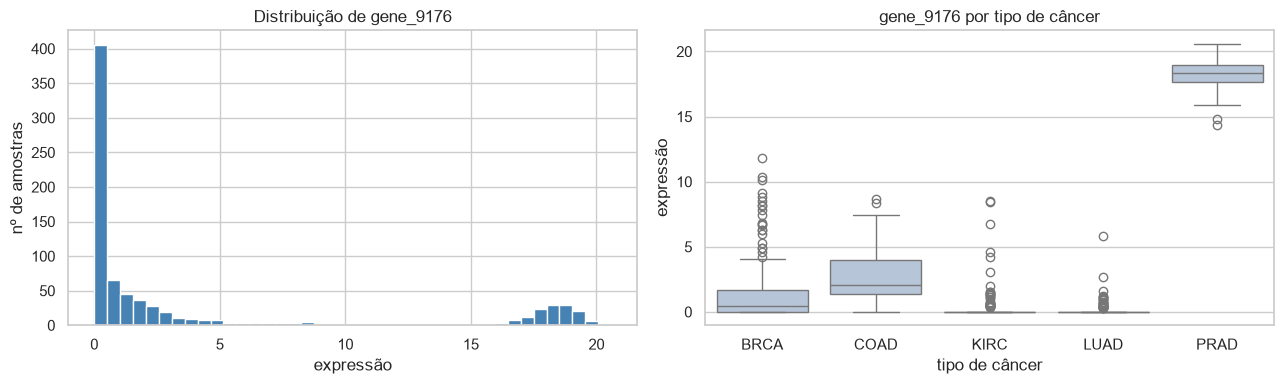

In [3]:
alvo = dados.var().idxmax()                     # gene de maior variância
y_all = dados[alvo]                             # resposta
X_all = dados.drop(columns=alvo)                # preditores: todos os outros genes

print(f"Gene a ser previsto (y): {alvo}")
print(f"Média = {y_all.mean():.2f} | desvio padrão = {y_all.std():.2f}")
print(f"Preditores candidatos: {X_all.shape[1]} genes")

classes = sorted(tipo.unique())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(y_all, bins=40, color="steelblue")
ax[0].set(title=f"Distribuição de {alvo}", xlabel="expressão", ylabel="nº de amostras")
sns.boxplot(x=tipo, y=y_all, order=classes, ax=ax[1], color="lightsteelblue")
ax[1].set(title=f"{alvo} por tipo de câncer", xlabel="tipo de câncer", ylabel="expressão")
plt.tight_layout(); plt.show()

### 1.2 Treino e teste

- 75% treino / 25% teste. Estratificamos pelo **tipo de câncer** para manter as proporções.
- **Tudo** o que for "aprendido" (seleção de genes, padronização, coeficientes, escolha de λ) usa **só o treino**. O teste fica guardado para a avaliação final.

### 1.3 Reduzindo para 2.000 genes candidatos

Ajustar o lasso com 20 mil genes é possível, mas lento aqui pra nossa aula. Vamos manter os **2.000 genes de maior variância no treino**. Mesmo assim, teremos **p = 2.000 preditores** para **n = 600 amostras de treino**: continuamos com **p > n**, que é exatamente a situação em que ridge e lasso vão bem.

In [4]:
X_tr_all, X_te_all, y_tr, y_te, tipo_tr, tipo_te = train_test_split(
    X_all, y_all, tipo, test_size=0.25, stratify=tipo, random_state=SEED)

P = 2000
genes = X_tr_all.var().sort_values(ascending=False).index[:P]   # variância calculada SÓ no treino
X_tr, X_te = X_tr_all[genes], X_te_all[genes]

n = X_tr.shape[0]
print(f"Treino: n = {n} amostras × p = {X_tr.shape[1]} genes")
print(f"Teste : {X_te.shape[0]} amostras")

Treino: n = 600 amostras × p = 2000 genes
Teste : 201 amostras


---
## Parte 2 — Regressão linear simples (1 gene)

Começamos pelo modelo mais simples: **um único gene** como preditor. Escolhemos o gene com **maior correlação** com a resposta, **no treino**.

$$\hat{y} = \beta_0 + \beta_1 x$$

Métricas (como nos slides):

- **RSS** = Σ (yᵢ − ŷᵢ)² — soma dos quadrados dos resíduos;
- **RSE** = √(RSS / (n − 2)) — desvio padrão estimado do erro. **n − 2** porque estimamos 2 parâmetros (β₀ e β₁);
- **R²** = 1 − RSS / TSS — fração da variação de *y* explicada pelo modelo (TSS = Σ (yᵢ − ȳ)²).

Gene mais correlacionado com gene_9176: gene_9175  (|r| = 0.980)

Modelo: ŷ = -0.139 + 1.082 × gene_9175
RSS  = 1065.1
RSE  = √(RSS / (n − 2)) = √(1065.1 / 598) = 1.335
R² treino = 1 − RSS/TSS = 1 − 1065.1/26704.5 = 0.960
R² teste  = 1 − RSS/TSS = 1 − 403.0/9104.3 = 0.956
r2_score no treino: 0.960 | no teste: 0.956


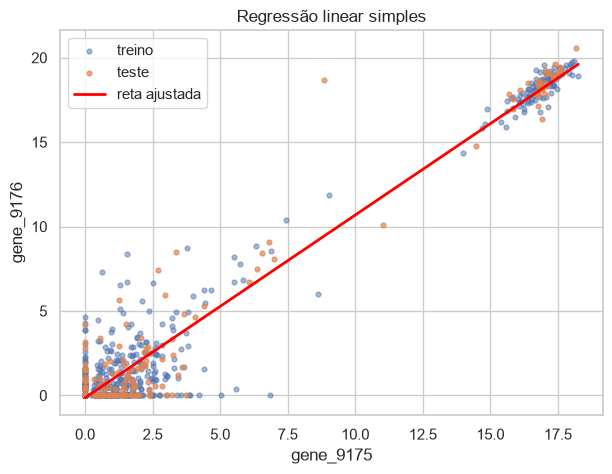

In [5]:
correl = X_tr.corrwith(y_tr).abs().sort_values(ascending=False)   # |correlação| de cada gene com y
g1 = correl.index[0]
print(f"Gene mais correlacionado com {alvo}: {g1}  (|r| = {correl.iloc[0]:.3f})\n")

simples = LinearRegression().fit(X_tr[[g1]], y_tr)
b0, b1 = simples.intercept_, simples.coef_[0]

# Treino
pred_tr = simples.predict(X_tr[[g1]])
RSS = ((y_tr - pred_tr) ** 2).sum()
TSS = ((y_tr - y_tr.mean()) ** 2).sum()
RSE = np.sqrt(RSS / (n - 2))

# Teste
pred_te = simples.predict(X_te[[g1]])
RSS_te = ((y_te - pred_te) ** 2).sum()
TSS_te = ((y_te - y_te.mean()) ** 2).sum()

print(f"Modelo: ŷ = {b0:.3f} + {b1:.3f} × {g1}")
print(f"RSS  = {RSS:.1f}")
print(f"RSE  = √(RSS / (n − 2)) = √({RSS:.1f} / {n - 2}) = {RSE:.3f}")
print(f"R² treino = 1 − RSS/TSS = 1 − {RSS:.1f}/{TSS:.1f} = {1 - RSS / TSS:.3f}")
print(f"R² teste  = 1 − RSS/TSS = 1 − {RSS_te:.1f}/{TSS_te:.1f} = {1 - RSS_te / TSS_te:.3f}")

# Conferência: a função do scikit-learn dá o mesmo valor
print(f"r2_score no treino: {r2_score(y_tr, pred_tr):.3f} | no teste: {r2_score(y_te, pred_te):.3f}")

xs = np.linspace(X_tr[g1].min(), X_tr[g1].max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(X_tr[g1], y_tr, s=12, alpha=0.5, label="treino")
plt.scatter(X_te[g1], y_te, s=12, alpha=0.7, label="teste")
plt.plot(xs, b0 + b1 * xs, c="red", lw=2, label="reta ajustada")
plt.xlabel(g1); plt.ylabel(alvo); plt.title("Regressão linear simples"); plt.legend(); plt.show()

---
## Parte 3 — Regressão linear múltipla: o problema quando p ≈ n

Agora usamos **vários genes** ao mesmo tempo, pelo método dos **mínimos quadrados** (minimizar o RSS, sem penalidade):

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

Vamos aumentar o número de genes **p** (sempre os mais correlacionados com *y*, no treino) e observar o erro no **treino** e no **teste**.

O RSE agora usa **n − p − 1** no denominador (p coeficientes + o intercepto). O que acontece quando p chega perto de n = 600?

In [6]:
lista_p = [1, 5, 10, 25, 50, 100, 200, 300, 400, 500, 560, 590, 599, 650, 800, 1000, 1500, 2000]

linhas = []
for p in lista_p:
    gs = correl.index[:p]                                   # os p genes mais correlacionados (treino)
    ols = LinearRegression().fit(X_tr[gs], y_tr)
    rss = ((y_tr - ols.predict(X_tr[gs])) ** 2).sum()
    gl = n - p - 1                                          # graus de liberdade do erro
    linhas.append({"p (nº de genes)": p,
                   "MSE treino": mean_squared_error(y_tr, ols.predict(X_tr[gs])),
                   "MSE teste":  mean_squared_error(y_te, ols.predict(X_te[gs])),
                   "R² treino":  r2_score(y_tr, ols.predict(X_tr[gs])),
                   "R² teste":   r2_score(y_te, ols.predict(X_te[gs])),
                   "n − p − 1":  gl,
                   "RSE":        np.sqrt(rss / gl) if gl > 0 else np.nan})
ols_tab = pd.DataFrame(linhas).set_index("p (nº de genes)")
display(ols_tab.round(3))

,MSE treino,MSE teste,R² treino,R² teste,n − p − 1,RSE
p (nº de genes),,,,,,
1,1.775,2.005,0.960,0.956,598,1.335
5,1.648,1.800,0.963,0.960,594,1.290
10,1.464,1.565,0.967,0.965,589,1.221
25,1.142,1.272,0.974,0.972,574,1.093
50,0.959,1.199,0.978,0.974,549,1.024
100,0.824,1.320,0.981,0.971,499,0.995
200,0.602,1.317,0.986,0.971,399,0.951
300,0.444,1.901,0.990,0.958,299,0.944
400,0.283,2.852,0.994,0.937,199,0.924


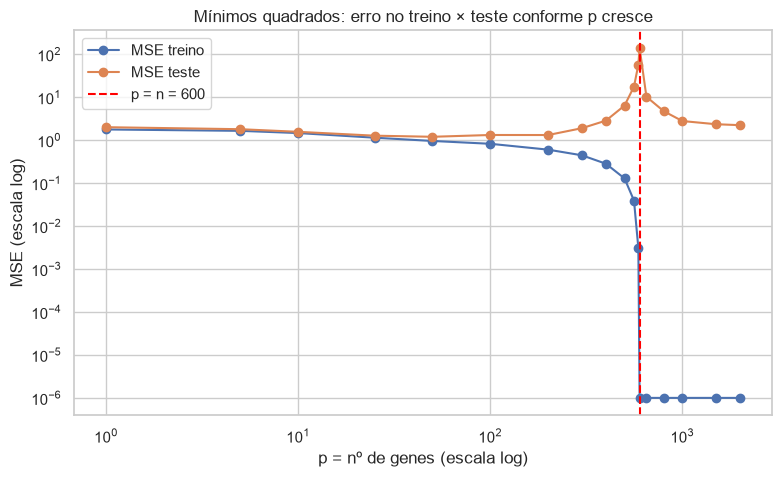

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ols_tab.index, ols_tab["MSE treino"] + 1e-6, "o-", label="MSE treino")
ax.plot(ols_tab.index, ols_tab["MSE teste"], "o-", label="MSE teste")
ax.axvline(n, c="red", ls="--", label=f"p = n = {n}")
ax.set(xscale="log", yscale="log", xlabel="p = nº de genes (escala log)", ylabel="MSE (escala log)",
       title="Mínimos quadrados: erro no treino × teste conforme p cresce")
ax.legend(); plt.show()

**O que aconteceu?**

- Conforme **p** cresce, o erro de **treino** só cai. Quando **p ≥ n − 1**, ele chega a **zero**: com mais coeficientes do que amostras, sempre existe uma combinação de genes que passa **exatamente** por todos os pontos de treino (lembre do caso de 2 pontos e uma reta).
- Nesse ponto, **n − p − 1 ≤ 0**: o RSE nem pode ser calculado. Não sobra nenhuma informação para estimar o erro.
- O erro de **teste**, por outro lado, **explode** perto de p ≈ n. O modelo decorou o treino (**sobreajuste**, alta **variância**).
- Com **p > n**, existem **infinitas** soluções de mínimos quadrados com erro de treino zero. O scikit-learn escolhe uma delas (a de menor norma), mas nenhuma é confiável.
- Talvez você note que, depois de p = n, o erro de teste volta a cair um pouco. Esse comportamento curioso (*double descent*) é tema de pesquisa recente e fica fora do escopo desta aula: o importante é que, perto de p ≈ n, os mínimos quadrados são instáveis.

É aqui que entram **ridge** e **lasso**: eles mudam o critério de "minimizar o RSS" para

$$\text{RSS} + \lambda \times \text{penalidade}(\beta)$$

e o termo de penalidade impede que os coeficientes fiquem enormes.

---
## Parte 4 — Por que L1 (lasso) zera coeficientes e L2 (ridge) não?

| | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Critério minimizado | RSS + λ Σ **βⱼ²** | RSS + λ Σ **\|βⱼ\|** |
| Penalidade | quadrado | módulo |
| Efeito nos coeficientes | encolhe todos, **nenhum** chega a zero | encolhe e **zera** vários (seleção de variáveis) |

### A ideia em uma frase

Cada coeficiente β gera uma **penalidade**: β² no ridge e |β| no lasso. O λ multiplica essa penalidade e define o quanto ela pesa no critério. As duas penalidades "cobram" pelo tamanho dos coeficientes, mas de jeitos diferentes **quando o coeficiente já é pequeno**:

- **Ridge (β²):** um coeficiente pequeno quase não custa nada. Por exemplo, 0,1² = 0,01. Zerar esse coeficiente economiza muito pouco, então o modelo prefere deixá-lo pequeno, mas diferente de zero.
- **Lasso (|β|):** um coeficiente pequeno continua custando o seu próprio tamanho, |0,1| = 0,1, ou seja, **10 vezes mais** que no ridge. Zerar esse coeficiente compensa, e por isso o lasso leva os coeficientes pouco úteis **exatamente para zero**.

O gráfico abaixo mostra isso: à esquerda, a forma das duas penalidades; à direita, quanto a penalidade diminui quando zeramos um coeficiente de tamanho 1, 0,5 ou 0,1.

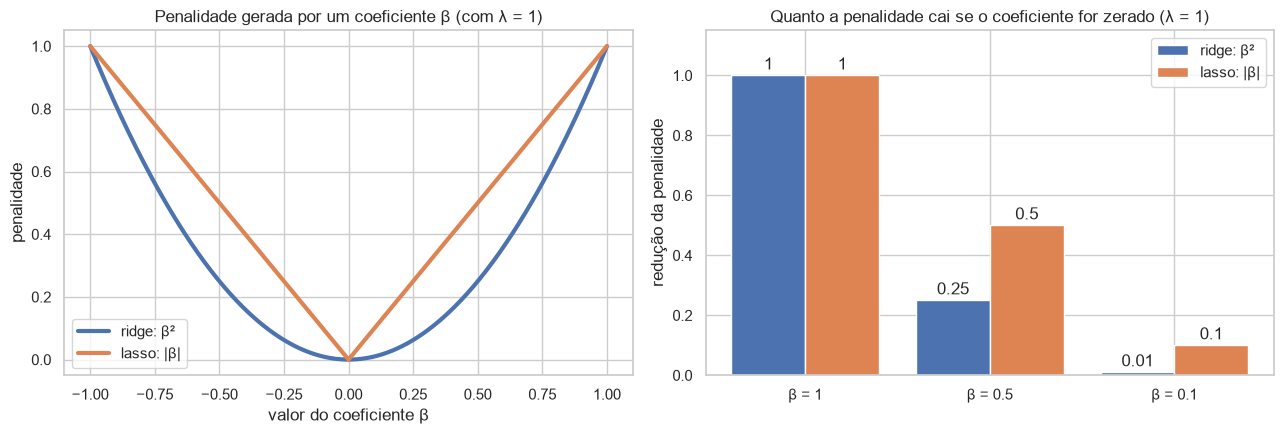

In [8]:
b = np.linspace(-1, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Esquerda: a forma das penalidades
ax[0].plot(b, b ** 2, lw=3, label="ridge: β²")
ax[0].plot(b, np.abs(b), lw=3, label="lasso: |β|")
ax[0].set(title="Penalidade gerada por um coeficiente β (com λ = 1)", xlabel="valor do coeficiente β", ylabel="penalidade")
ax[0].legend()

# Direita: quanto se economiza ao zerar um coeficiente de cada tamanho
valores = [1, 0.5, 0.1]
x = np.arange(len(valores))
ax[1].bar(x - 0.2, [v ** 2 for v in valores], width=0.4, label="ridge: β²")
ax[1].bar(x + 0.2, valores, width=0.4, label="lasso: |β|")
for i, v in enumerate(valores):
    ax[1].text(i - 0.2, v ** 2 + 0.02, f"{v**2:g}", ha="center")
    ax[1].text(i + 0.2, v + 0.02, f"{v:g}", ha="center")
ax[1].set_xticks(x, [f"β = {v:g}" for v in valores])
ax[1].set(title="Quanto a penalidade cai se o coeficiente for zerado (λ = 1)",
          ylabel="redução da penalidade", ylim=(0, 1.15))
ax[1].legend()
plt.tight_layout(); plt.show()

**O que observar:**

- Perto de zero, a curva do **ridge** é quase plana: a penalidade praticamente não muda entre β = 0,1 e β = 0. Não há motivo para "empurrar" o coeficiente até o zero.
- A curva do **lasso** tem um **bico** em zero e continua inclinada até o final. Para coeficientes pequenos, zerar ainda vale a pena.

### Vendo isso acontecer

Agora um exemplo com dois coeficientes (β₁ e β₂) e valores crescentes de λ. Os dados são simulados: β₁ é um preditor importante e β₂, um preditor menos importante.

C:\Users\night\AppData\Local\Temp\ipykernel_14960\2171746172.py:25: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\night\AppData\Local\Temp\ipykernel_14960\2171746172.py:25: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
c:\Users\night\OneDrive\Área de Trabalho\PROJETOS GITHUB\bioinformatics-task\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\night\OneDrive\Área de Trabalho\PROJETOS GITHUB\bioinformatics-task\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


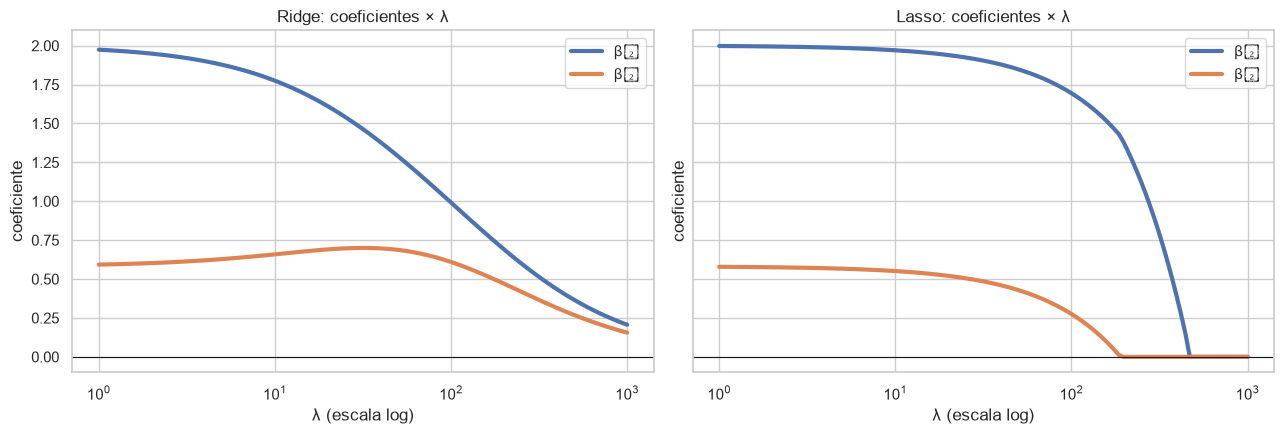

In [9]:
from sklearn.linear_model import Lasso

# Dados simulados: 2 preditores correlacionados, y = 2·x1 + 0,6·x2 + ruído
rng = np.random.default_rng(1)
n2 = 100
x1 = rng.normal(size=n2)
x2 = 0.7 * x1 + np.sqrt(1 - 0.7 ** 2) * rng.normal(size=n2)
X2 = np.c_[x1, x2]
X2 = (X2 - X2.mean(0)) / X2.std(0)                     # padroniza os preditores
y2 = 2.0 * X2[:, 0] + 0.6 * X2[:, 1] + rng.normal(scale=1.0, size=n2)
y2 = y2 - y2.mean()

# Ajusta ridge e lasso para vários valores de λ
lams = np.logspace(0, 3, 120)
ridge = np.array([np.linalg.solve(X2.T @ X2 + l * np.eye(2), X2.T @ y2) for l in lams])
lasso = np.array([Lasso(alpha=l / (2 * n2), fit_intercept=False).fit(X2, y2).coef_ for l in lams])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, coefs, nome in [(ax[0], ridge, "Ridge"), (ax[1], lasso, "Lasso")]:
    a.plot(lams, coefs[:, 0], lw=3, label="β₁")
    a.plot(lams, coefs[:, 1], lw=3, label="β₂")
    a.axhline(0, c="k", lw=0.8)
    a.set(xscale="log", title=f"{nome}: coeficientes × λ", xlabel="λ (escala log)", ylabel="coeficiente")
    a.legend()
plt.tight_layout(); plt.show()

**O que observar:**

- **Ridge:** conforme λ cresce, os dois coeficientes diminuem juntos e vão se **aproximando** de zero, mas nunca chegam lá.
- **Lasso:** o coeficiente menos importante (β₂) chega a **zero** primeiro e fica lá; com λ ainda maior, β₁ também zera.

É por isso que o lasso faz **seleção de variáveis**: os genes pouco úteis ficam com coeficiente exatamente zero e saem do modelo. O ridge mantém todos os genes, só que com coeficientes menores.

---
## Parte 5 — Ridge e lasso nos genes: caminhos dos coeficientes

Agora voltamos aos dados reais: **n = 600** amostras de treino e **p = 2.000** genes.

### Por que padronizar?

A penalidade soma os coeficientes de todos os genes. Se um gene tem valores grandes, seu coeficiente fica pequeno "naturalmente" e é menos penalizado. Para a penalidade tratar todos os genes **de forma justa**, colocamos cada gene na mesma escala (média 0, desvio padrão 1) com o `StandardScaler`, ajustado **só no treino**. Os coeficientes resultantes são os **coeficientes padronizados** dos gráficos dos slides.

### Uma observação sobre o λ do scikit-learn

O scikit-learn chama λ de `alpha`, e as escalas não são idênticas às dos slides:

- `Ridge(alpha)` minimiza **RSS + alpha · Σβ²** → `alpha` = λ;
- `Lasso(alpha)` minimiza **RSS / (2n) + alpha · Σ|β|** → λ = 2n · `alpha`.

Isso não muda nada na interpretação: maior `alpha` = penalidade mais forte.

In [10]:
escala = StandardScaler().fit(X_tr)                      # média e desvio de cada gene (SÓ treino)
Xs_tr, Xs_te = escala.transform(X_tr), escala.transform(X_te)
ys_tr = y_tr - y_tr.mean()                               # y centralizado (o intercepto fica de fora da penalidade)

# 10 genes de destaque (os mais correlacionados com y) para colorir nos gráficos
destaque = [list(genes).index(g) for g in correl.index[:10]]

# ---- Caminho do ridge: um ajuste para cada λ ----
alphas_ridge = np.logspace(-1, 6, 40)
t0 = time.time()
coef_ridge = np.array([Ridge(alpha=a).fit(Xs_tr, ys_tr).coef_ for a in alphas_ridge])
print(f"Caminho do ridge: {len(alphas_ridge)} ajustes em {time.time() - t0:.1f} s")

# ---- Caminho do lasso: o scikit-learn tem uma função pronta ----
t0 = time.time()
alpha_max = np.abs(Xs_tr.T @ ys_tr).max() / n            # a partir deste valor, o lasso zera TODOS os genes
alphas_lasso = alpha_max * np.logspace(-3, 0, 40)
alphas_lasso, coef_lasso, _ = lasso_path(Xs_tr, ys_tr.to_numpy(), alphas=alphas_lasso, max_iter=5000)
coef_lasso = coef_lasso.T                                 # (nº de λ × nº de genes)
print(f"Caminho do lasso: {len(alphas_lasso)} valores de λ em {time.time() - t0:.1f} s")

Caminho do ridge: 40 ajustes em 2.1 s
Caminho do lasso: 40 valores de λ em 1.8 s


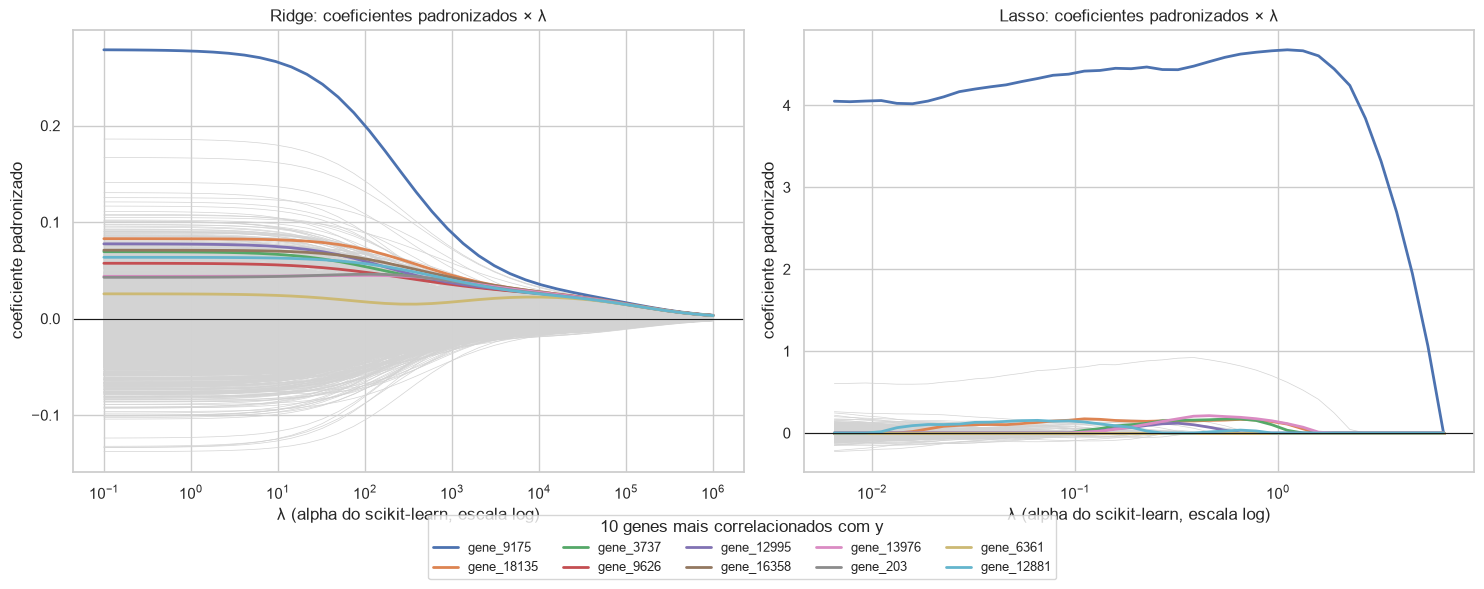

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, alphas, coefs, nome in [(ax[0], alphas_ridge, coef_ridge, "Ridge"),
                               (ax[1], alphas_lasso, coef_lasso, "Lasso")]:
    a.plot(alphas, coefs, c="lightgray", lw=0.5)                       # todos os 2.000 genes
    for j in destaque:                                                   # os 10 genes de destaque
        a.plot(alphas, coefs[:, j], lw=2, label=genes[j])
    a.axhline(0, c="k", lw=0.8)
    a.set(xscale="log", title=f"{nome}: coeficientes padronizados × λ",
          xlabel="λ (alpha do scikit-learn, escala log)", ylabel="coeficiente padronizado")
h, l = ax[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.08), title="10 genes mais correlacionados com y")
plt.tight_layout(); plt.show()

**Compare com os slides:**

- **Ridge:** conforme λ cresce, **todas** as curvas vão se aproximando de zero **suavemente**, mas nenhuma encosta no zero antes da outra.
- **Lasso:** as curvas **batem no zero e ficam lá**, uma de cada vez. Para λ grande, sobram pouquíssimos genes; no extremo direito, nenhum.
- No lasso, um coeficiente pode até **crescer** enquanto λ aumenta: quando um gene parecido é zerado, outro "assume" o papel dele.

O gráfico abaixo conta **quantos coeficientes são diferentes de zero** para cada λ.

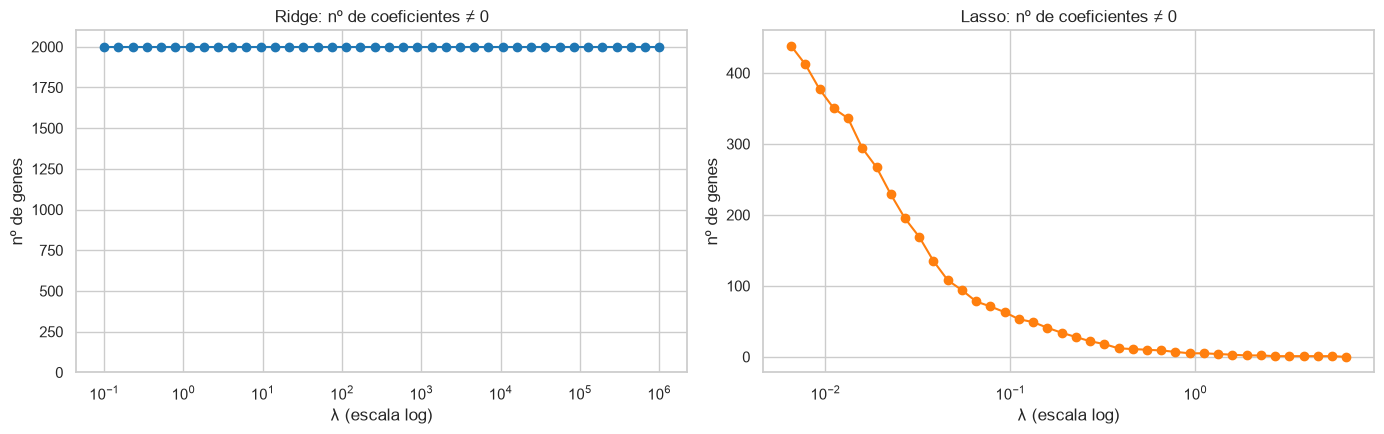

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(alphas_ridge, (np.abs(coef_ridge) > 1e-10).sum(axis=1), "o-", c="tab:blue")
ax[0].set(xscale="log", title="Ridge: nº de coeficientes ≠ 0", xlabel="λ (escala log)", ylabel="nº de genes",
          ylim=(0, P * 1.05))
ax[1].plot(alphas_lasso, (coef_lasso != 0).sum(axis=1), "o-", c="tab:orange")
ax[1].set(xscale="log", title="Lasso: nº de coeficientes ≠ 0", xlabel="λ (escala log)", ylabel="nº de genes")
plt.tight_layout(); plt.show()

---
## Parte 6 — Escolhendo λ por validação cruzada

λ controla o **compromisso entre viés e variância** (slide *bias-variance trade-off*):

- **λ pequeno** → quase mínimos quadrados: coeficientes livres, **alta variância** (sobreajuste);
- **λ grande** → coeficientes muito encolhidos: modelo rígido, **alto viés** (subajuste);
- o melhor λ fica no meio, onde o **erro de teste** é mínimo.

Como não podemos usar o teste para escolher λ, usamos **validação cruzada de 5 partes no treino**. Em cada parte, a padronização e o modelo são reajustados do zero (`Pipeline`).

> O lasso com λ pequeno e p > n converge devagar; por isso desligamos os avisos de convergência na Parte 0. Esta célula leva cerca de 1 a 2 minutos.

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def erro_cv(cria_modelo, alphas):
    # MSE médio de validação cruzada para cada λ
    erros = []
    for a in alphas:
        mses = []
        for i_tr, i_va in kf.split(X_tr):
            modelo = make_pipeline(StandardScaler(), cria_modelo(a))
            modelo.fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
            mses.append(mean_squared_error(y_tr.iloc[i_va], modelo.predict(X_tr.iloc[i_va])))
        erros.append(np.mean(mses))
    return np.array(erros)

t0 = time.time()
grade_ridge = np.logspace(-1, 6, 20)
grade_lasso = alpha_max * np.logspace(-3, 0, 20)
cv_ridge = erro_cv(lambda a: Ridge(alpha=a), grade_ridge)
cv_lasso = erro_cv(lambda a: Lasso(alpha=a, max_iter=5000), grade_lasso)
print(f"Validação cruzada concluída em {time.time() - t0:.0f} s")

melhor_ridge = grade_ridge[cv_ridge.argmin()]
melhor_lasso = grade_lasso[cv_lasso.argmin()]
print(f"Melhor λ do ridge: {melhor_ridge:.3g}  (MSE de validação = {cv_ridge.min():.3f})")
print(f"Melhor λ do lasso: {melhor_lasso:.3g}  (MSE de validação = {cv_lasso.min():.3f})")

Validação cruzada concluída em 48 s
Melhor λ do ridge: 1.13e+03  (MSE de validação = 1.821)
Melhor λ do lasso: 0.0579  (MSE de validação = 1.000)


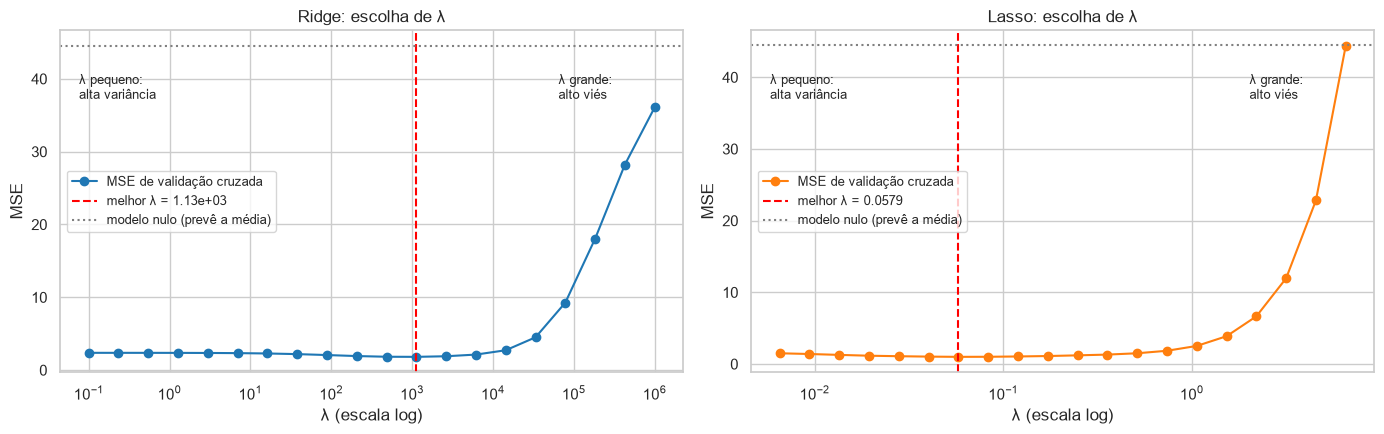

In [14]:
mse_nulo = mean_squared_error(y_tr, np.full(len(y_tr), y_tr.mean()))   # modelo que sempre prevê a média

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, grade, cv, melhor, nome, cor in [(ax[0], grade_ridge, cv_ridge, melhor_ridge, "Ridge", "tab:blue"),
                                        (ax[1], grade_lasso, cv_lasso, melhor_lasso, "Lasso", "tab:orange")]:
    a.plot(grade, cv, "o-", c=cor, label="MSE de validação cruzada")
    a.axvline(melhor, c="red", ls="--", label=f"melhor λ = {melhor:.3g}")
    a.axhline(mse_nulo, c="gray", ls=":", label="modelo nulo (prevê a média)")
    a.annotate("λ pequeno:\nalta variância", xy=(0.03, 0.8), xycoords="axes fraction", fontsize=9)
    a.annotate("λ grande:\nalto viés", xy=(0.80, 0.8), xycoords="axes fraction", fontsize=9)
    a.set(xscale="log", title=f"{nome}: escolha de λ", xlabel="λ (escala log)", ylabel="MSE")
    a.legend(fontsize=9, loc="center left")
plt.tight_layout(); plt.show()

---
## Parte 7 — Comparação final no conjunto de teste

Ajustamos os modelos finais no treino inteiro (com o λ escolhido) e avaliamos **uma única vez** no teste:

| Modelo | Preditores |
|---|---|
| Regressão linear simples | 1 gene (o mais correlacionado) |
| Mínimos quadrados | os 2.000 genes, sem penalidade |
| Ridge | os 2.000 genes, penalidade L2 |
| Lasso | os 2.000 genes, penalidade L1 |

In [15]:
modelos = {
    "Linear simples (1 gene)": (LinearRegression(), [g1]),
    "Mínimos quadrados (2.000 genes)": (make_pipeline(StandardScaler(), LinearRegression()), list(genes)),
    "Ridge (2.000 genes)": (make_pipeline(StandardScaler(), Ridge(alpha=melhor_ridge)), list(genes)),
    "Lasso (2.000 genes)": (make_pipeline(StandardScaler(), Lasso(alpha=melhor_lasso, max_iter=10000)), list(genes)),
}

resultado, previsoes = [], {}
for nome, (modelo, cols) in modelos.items():
    modelo.fit(X_tr[cols], y_tr)
    previsoes[nome] = modelo.predict(X_te[cols])
    coefs = modelo[-1].coef_ if hasattr(modelo, "steps") else modelo.coef_
    resultado.append({"modelo": nome,
                      "genes usados (coef. ≠ 0)": int((np.abs(coefs) > 1e-10).sum()),
                      "R² treino": r2_score(y_tr, modelo.predict(X_tr[cols])),
                      "R² teste": r2_score(y_te, previsoes[nome]),
                      "MSE teste": mean_squared_error(y_te, previsoes[nome])})
resultado = pd.DataFrame(resultado).set_index("modelo")
display(resultado.round(3))

,genes usados (coef. ≠ 0),R² treino,R² teste,MSE teste
modelo,,,,
Linear simples (1 gene),1,0.960,0.956,2.005
Mínimos quadrados (2.000 genes),2000,1.000,0.942,2.623
Ridge (2.000 genes),2000,0.983,0.957,1.960
Lasso (2.000 genes),90,0.986,0.975,1.147


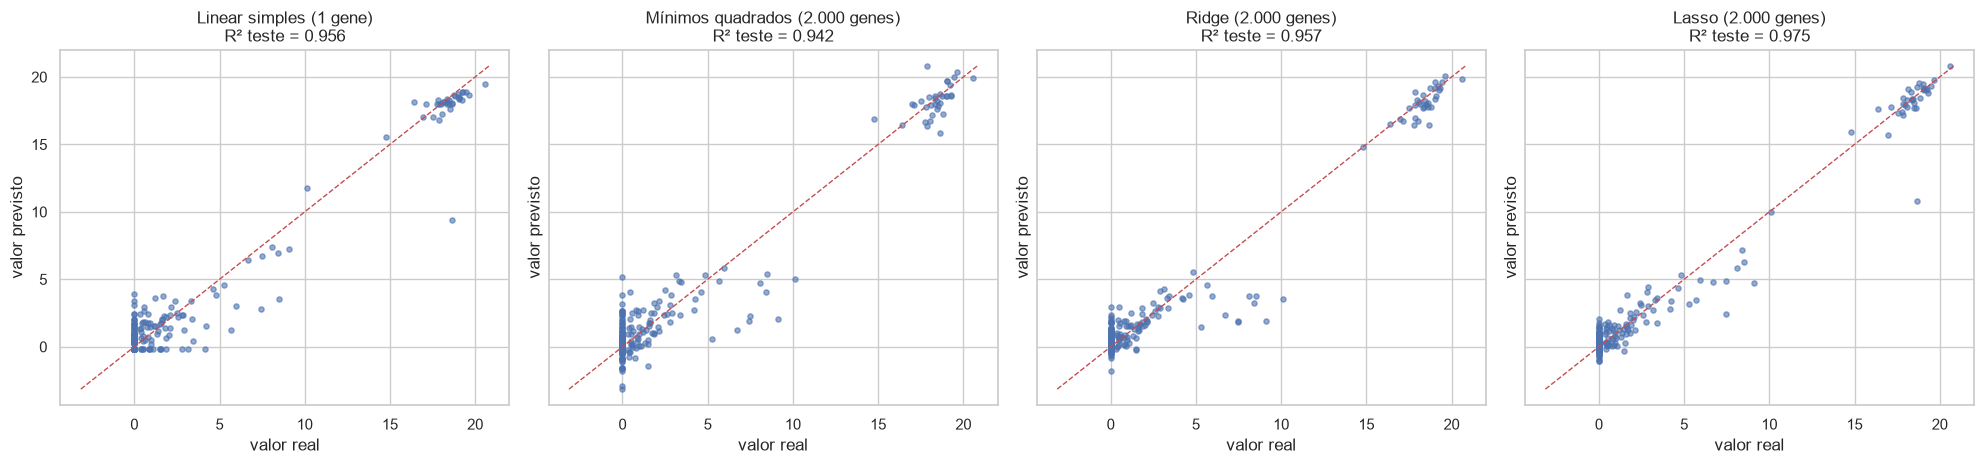

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
lim = [min(y_te.min(), min(p.min() for p in previsoes.values())), max(y_te.max(), max(p.max() for p in previsoes.values()))]
for a, (nome, pred) in zip(ax, previsoes.items()):
    a.scatter(y_te, pred, s=14, alpha=0.6)
    a.plot(lim, lim, "r--", lw=1)                                   # linha perfeita: previsto = real
    a.set(title=f"{nome}\nR² teste = {r2_score(y_te, pred):.3f}", xlabel="valor real", ylabel="valor previsto")
plt.tight_layout(); plt.show()

**Para pensar:**

- Os **mínimos quadrados** com 2.000 genes têm R² de treino próximo de 1. E no teste? O que isso diz sobre usar só o erro de treino para avaliar um modelo?
- Ridge e lasso usam os **mesmos** 2.000 genes candidatos. Qual teve o melhor R² de teste? A diferença é grande?
- O lasso usou **quantos** genes? E o ridge? Se você fosse levar o modelo para um laboratório medir os genes, qual preferiria?

---
## Parte 8 — Quais genes o lasso escolheu?

O lasso faz **seleção de variáveis**: só os genes com coeficiente ≠ 0 entram no modelo. Isso facilita muito a **interpretação** (slide: *"Models generated from the lasso are generally much easier to interpret"*).

In [17]:
coef_r = pd.Series(modelos["Ridge (2.000 genes)"][0][-1].coef_, index=genes)
coef_l = pd.Series(modelos["Lasso (2.000 genes)"][0][-1].coef_, index=genes)

escolhidos = coef_l[coef_l != 0].sort_values(key=np.abs, ascending=False)
print(f"O lasso manteve {len(escolhidos)} dos {P} genes.\n")

tab = pd.DataFrame({"coef. lasso": escolhidos.head(15),
                    "coef. ridge": coef_r[escolhidos.head(15).index],
                    "|correlação| com y": correl[escolhidos.head(15).index]})
display(tab.round(3).rename_axis("genes com maior |coef.| no lasso (até 15)"))

no_top10 = len(set(escolhidos.index) & set(correl.index[:10]))
print(f"Dos 10 genes mais correlacionados com y, {no_top10} foram mantidos pelo lasso.")

O lasso manteve 90 dos 2000 genes.



,coef. lasso,coef. ridge,|correlação| com y
genes com maior |coef.| no lasso (até 15),,,
gene_9175,4.287,0.084,0.980
gene_9173,0.750,0.070,0.870
gene_12881,0.160,0.039,0.903
gene_9169,0.156,0.050,0.593
gene_3730,0.147,0.035,0.790
gene_11277,0.136,0.034,0.511
gene_17287,0.119,0.034,0.497
gene_9174,0.114,0.059,0.367
gene_18135,0.109,0.044,0.944


Dos 10 genes mais correlacionados com y, 3 foram mantidos pelo lasso.


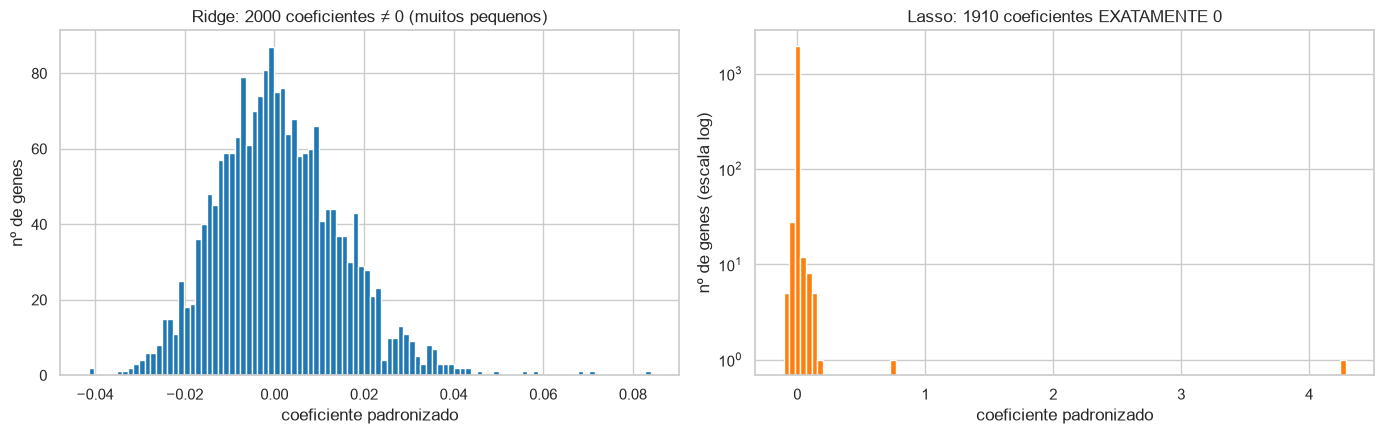

In [18]:
# A diferença L1 × L2 em um único gráfico: a distribuição dos 2.000 coeficientes
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(coef_r, bins=100, color="tab:blue")
ax[0].set(title=f"Ridge: {int((np.abs(coef_r) > 1e-10).sum())} coeficientes ≠ 0 (muitos pequenos)",
          xlabel="coeficiente padronizado", ylabel="nº de genes")
ax[1].hist(coef_l, bins=100, color="tab:orange")
ax[1].set(title=f"Lasso: {int((coef_l == 0).sum())} coeficientes EXATAMENTE 0",
          xlabel="coeficiente padronizado", ylabel="nº de genes (escala log)", yscale="log")
plt.tight_layout(); plt.show()

---
## Parte 9 — Resumo

| | Mínimos quadrados | Ridge (L2) | Lasso (L1) |
|---|---|---|---|
| Critério | RSS | RSS + λ Σ βⱼ² | RSS + λ Σ \|βⱼ\| |
| Funciona com p > n? | **Não** (infinitas soluções, sobreajuste) | Sim | Sim |
| Coeficientes | livres | encolhidos, **nenhum zero** | encolhidos, **vários exatamente zero** |
| Por quê? | — | a força da penalidade (2β) some perto de 0 | a força da penalidade (±1) é constante até 0 |
| Geometria | — | círculo (sem bicos) | losango (bicos sobre os eixos) |
| Seleção de variáveis | não | não | **sim** |
| Genes parecidos (correlacionados) | instável | divide o peso entre eles | tende a escolher um |
| Escolha de λ | — | validação cruzada | validação cruzada |

---
## Exercícios

1. **Outro gene.** Troque o gene-alvo pelo **10º gene de maior variância** (`dados.var().sort_values(ascending=False).index[9]`) e refaça os experimentos. Os resultados mudam muito?
2. **Elastic net.** O `ElasticNet` (de `sklearn.linear_model`) combina as duas penalidades: λ [ α Σ|β| + (1 − α) Σβ² ]. Teste `l1_ratio` = 0,2, 0,5 e 0,8 com o mesmo `alpha` do lasso. Quantos genes cada um mantém?
3. **Sem padronizar.** Refaça os testes sem o `StandardScaler` no ridge e no lasso. O que acontece com o R² de teste e com o número de genes do lasso? Por quê?
4. **Com suas palavras** (máx. 5 linhas): explique para um colega por que a penalidade |β| zera coeficientes e a penalidade β² não.

---
*Referências:* James, Witten, Hastie & Tibshirani, *An Introduction to Statistical Learning* (cap. 6); Weinstein *et al.* (2013), *The Cancer Genome Atlas Pan-Cancer analysis project*, Nature Genetics 45:1113–1120; UCI Machine Learning Repository — *Gene Expression Cancer RNA-Seq* (ID 401).

---
## Resolução dos Exercícios

### Exercício 1 — Outro gene (10º gene de maior variância)

10º gene de maior variância (alvo): gene_15897 | média = 5.71 | desvio = 5.10
Gene mais correlacionado com gene_15897: gene_15896 (|r| = 0.842)
Melhor lambda Ridge: 483 (MSE CV = 2.992)
Melhor lambda Lasso: 0.0808 (MSE CV = 2.212)



,genes usados (coef. ≠ 0),R² treino,R² teste,MSE teste
modelo,,,,
Linear simples (1 gene),1,0.710,0.682,6.918
Mínimos quadrados (2.000 genes),2000,1.000,0.847,3.338
Ridge (2.000 genes),2000,0.974,0.878,2.652
Lasso (2.000 genes),105,0.950,0.921,1.714


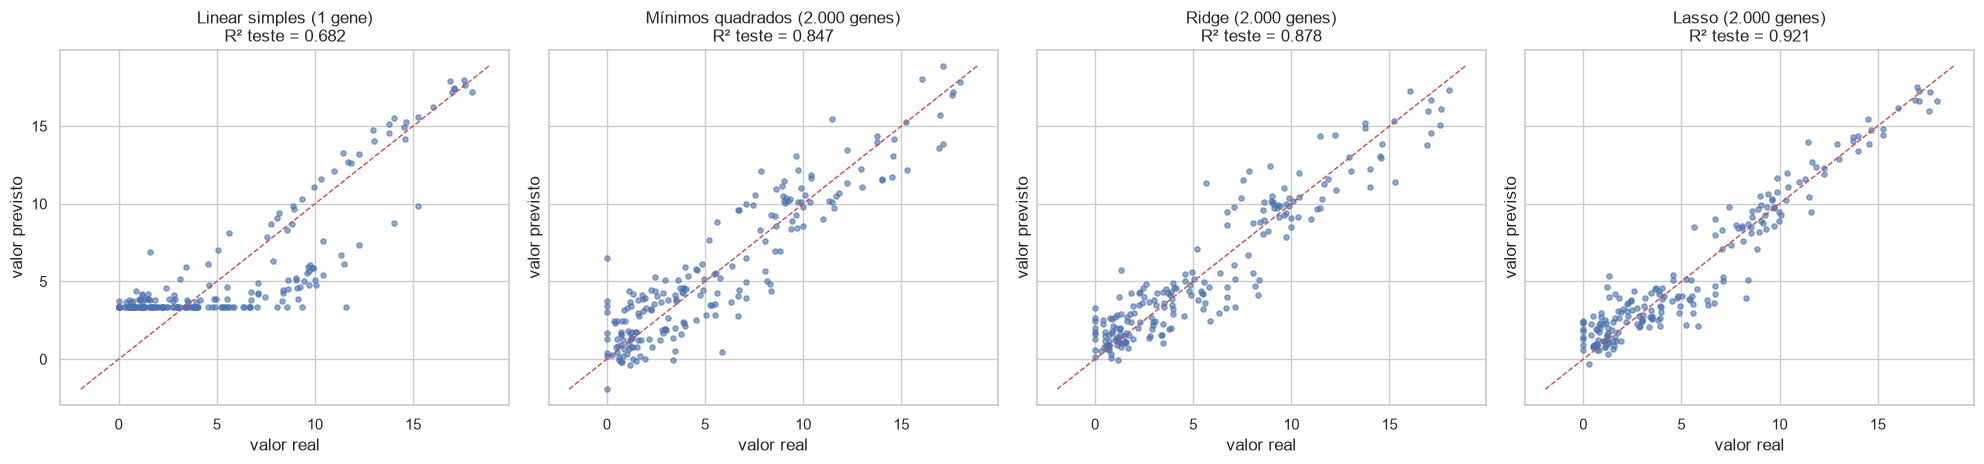

In [19]:
# ---------------------------------------------------------------
# Exercício 1 — Repetindo o experimento com o 10º gene de maior variância
# ---------------------------------------------------------------
alvo10 = dados.var().sort_values(ascending=False).index[9]
y10_all = dados[alvo10]
X10_all = dados.drop(columns=alvo10)
print(f"10º gene de maior variância (alvo): {alvo10} | média = {y10_all.mean():.2f} | desvio = {y10_all.std():.2f}")

# Mesma divisão estratificada (75% treino / 25% teste) e seleção dos 2.000 genes mais variáveis só no treino
X10_tr_all, X10_te_all, y10_tr, y10_te = train_test_split(
    X10_all, y10_all, test_size=0.25, stratify=tipo, random_state=SEED
)
genes10 = X10_tr_all.var().sort_values(ascending=False).index[:P]
X10_tr, X10_te = X10_tr_all[genes10], X10_te_all[genes10]

# Gene mais correlacionado no treino para a regressão linear simples
correl10 = X10_tr.corrwith(y10_tr).abs().sort_values(ascending=False)
g1_10 = correl10.index[0]
print(f"Gene mais correlacionado com {alvo10}: {g1_10} (|r| = {correl10.iloc[0]:.3f})")

# Escolha de lambda (alpha) por validação cruzada de 5 folds apenas no treino
Xs10_tr = StandardScaler().fit_transform(X10_tr)
ys10_tr = y10_tr - y10_tr.mean()
alpha_max_10 = np.abs(Xs10_tr.T @ ys10_tr).max() / len(X10_tr)

grade_ridge_10 = np.logspace(-1, 6, 20)
grade_lasso_10 = alpha_max_10 * np.logspace(-3, 0, 20)

def erro_cv_dados(X_data, y_data, cria_modelo, alphas):
    erros = []
    for a in alphas:
        mses = []
        for i_tr, i_va in kf.split(X_data):
            mod = make_pipeline(StandardScaler(), cria_modelo(a))
            mod.fit(X_data.iloc[i_tr], y_data.iloc[i_tr])
            mses.append(mean_squared_error(y_data.iloc[i_va], mod.predict(X_data.iloc[i_va])))
        erros.append(np.mean(mses))
    return np.array(erros)

cv_r10 = erro_cv_dados(X10_tr, y10_tr, lambda a: Ridge(alpha=a), grade_ridge_10)
cv_l10 = erro_cv_dados(X10_tr, y10_tr, lambda a: Lasso(alpha=a, max_iter=5000), grade_lasso_10)
melhor_ridge_10 = grade_ridge_10[cv_r10.argmin()]
melhor_lasso_10 = grade_lasso_10[cv_l10.argmin()]
print(f"Melhor lambda Ridge: {melhor_ridge_10:.3g} (MSE CV = {cv_r10.min():.3f})")
print(f"Melhor lambda Lasso: {melhor_lasso_10:.3g} (MSE CV = {cv_l10.min():.3f})\n")

# Comparação final no conjunto de teste
modelos_10 = {
    "Linear simples (1 gene)": (LinearRegression(), [g1_10]),
    "Mínimos quadrados (2.000 genes)": (make_pipeline(StandardScaler(), LinearRegression()), list(genes10)),
    "Ridge (2.000 genes)": (make_pipeline(StandardScaler(), Ridge(alpha=melhor_ridge_10)), list(genes10)),
    "Lasso (2.000 genes)": (make_pipeline(StandardScaler(), Lasso(alpha=melhor_lasso_10, max_iter=10000)), list(genes10)),
}

res_10, prev_10 = [], {}
for nome, (mod, cols) in modelos_10.items():
    mod.fit(X10_tr[cols], y10_tr)
    prev_10[nome] = mod.predict(X10_te[cols])
    coefs = mod[-1].coef_ if hasattr(mod, "steps") else mod.coef_
    res_10.append({
        "modelo": nome,
        "genes usados (coef. ≠ 0)": int((np.abs(coefs) > 1e-10).sum()),
        "R² treino": r2_score(y10_tr, mod.predict(X10_tr[cols])),
        "R² teste": r2_score(y10_te, prev_10[nome]),
        "MSE teste": mean_squared_error(y10_te, prev_10[nome]),
    })
res_10 = pd.DataFrame(res_10).set_index("modelo")
display(res_10.round(3))

# Gráfico real x previsto no teste para o 10º gene
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
lim = [min(y10_te.min(), min(p.min() for p in prev_10.values())),
       max(y10_te.max(), max(p.max() for p in prev_10.values()))]
for a, (nome, pred) in zip(ax, prev_10.items()):
    a.scatter(y10_te, pred, s=14, alpha=0.6)
    a.plot(lim, lim, "r--", lw=1)
    a.set(title=f"{nome}\nR² teste = {r2_score(y10_te, pred):.3f}", xlabel="valor real", ylabel="valor previsto")
plt.tight_layout(); plt.show()

Resposta do Exercício 1:

Sim, os resultados mudam de forma bem perceptível em relação ao gene_9176. O 10º gene de maior variância é o gene_15897, cujo preditor mais correlacionado (gene_15896) tem correlação menor (0,842, contra 0,980 no caso anterior). Por isso, a regressão linear simples com apenas 1 gene cai bastante no teste, indo de R² = 0,956 para 0,682 (MSE = 6,918).

Nesse cenário, usar vários genes com regularização traz um ganho muito maior: os mínimos quadrados com 2.000 genes decoram o treino (R² = 1,000) e ficam em 0,847 no teste, o Ridge sobe para 0,878 (MSE = 2,652) e o Lasso chega a 0,921 no teste (MSE = 1,714), reduzindo o erro a um quarto do modelo simples usando apenas 105 genes.

### Exercício 2 — Elastic Net

In [20]:
# ---------------------------------------------------------------
# Exercício 2 — ElasticNet combinando penalidade L1 (Lasso) e L2 (Ridge)
# ---------------------------------------------------------------
from sklearn.linear_model import ElasticNet

linhas_en = []
for ratio in [0.2, 0.5, 0.8]:
    en = make_pipeline(StandardScaler(), ElasticNet(alpha=melhor_lasso, l1_ratio=ratio, max_iter=10000))
    en.fit(X_tr, y_tr)
    pred_te = en.predict(X_te)
    linhas_en.append({
        "modelo": f"ElasticNet (l1_ratio = {ratio})",
        "genes usados (coef. ≠ 0)": int((np.abs(en[-1].coef_) > 1e-10).sum()),
        "R² treino": r2_score(y_tr, en.predict(X_tr)),
        "R² teste": r2_score(y_te, pred_te),
        "MSE teste": mean_squared_error(y_te, pred_te),
    })

# Referência: Lasso puro (equivale a l1_ratio = 1.0) com o mesmo alpha
lasso_ref = make_pipeline(StandardScaler(), Lasso(alpha=melhor_lasso, max_iter=10000)).fit(X_tr, y_tr)
pred_ref = lasso_ref.predict(X_te)
linhas_en.append({
    "modelo": "Lasso puro (l1_ratio = 1.0)",
    "genes usados (coef. ≠ 0)": int((np.abs(lasso_ref[-1].coef_) > 1e-10).sum()),
    "R² treino": r2_score(y_tr, lasso_ref.predict(X_tr)),
    "R² teste": r2_score(y_te, pred_ref),
    "MSE teste": mean_squared_error(y_te, pred_ref),
})

tab_en = pd.DataFrame(linhas_en).set_index("modelo")
display(tab_en.round(3))

,genes usados (coef. ≠ 0),R² treino,R² teste,MSE teste
modelo,,,,
ElasticNet (l1_ratio = 0.2),493,0.995,0.959,1.835
ElasticNet (l1_ratio = 0.5),235,0.989,0.969,1.388
ElasticNet (l1_ratio = 0.8),144,0.987,0.974,1.170
Lasso puro (l1_ratio = 1.0),90,0.986,0.975,1.147


Resposta do Exercício 2:

Mantendo o mesmo alpha escolhido para o Lasso (0,0579), o número de genes mantidos diminui de forma progressiva conforme o peso da penalidade L1 aumenta: com l1_ratio = 0,2 o modelo mantém 493 genes (R² de teste = 0,959), com l1_ratio = 0,5 mantém 235 genes (R² de teste = 0,969) e com l1_ratio = 0,8 mantém 144 genes (R² de teste = 0,974), aproximando-se do Lasso puro (90 genes e R² de teste = 0,975).

Isso ocorre porque valores maiores de l1_ratio dão mais força ao termo L1 em relação ao L2, fazendo o modelo zerar mais coeficientes e se comportar de forma mais esparsa.

### Exercício 3 — Sem padronizar

In [21]:
# ---------------------------------------------------------------
# Exercício 3 — Ridge e Lasso SEM StandardScaler
# ---------------------------------------------------------------
# Parte A: sem padronizar mantendo os mesmos alphas da Parte 6
# Parte B: sem padronizar reescolhendo os alphas por validação cruzada (para comparação completa)
Xc_tr = X_tr - X_tr.mean(axis=0)
ys_tr_raw = y_tr - y_tr.mean()
alpha_max_raw = np.abs(Xc_tr.T @ ys_tr_raw).max() / len(X_tr)
grade_lasso_raw = alpha_max_raw * np.logspace(-3, 0, 20)

def erro_cv_sem_scaler(cria_modelo, alphas):
    erros = []
    for a in alphas:
        mses = []
        for i_tr, i_va in kf.split(X_tr):
            mod = cria_modelo(a)
            mod.fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
            mses.append(mean_squared_error(y_tr.iloc[i_va], mod.predict(X_tr.iloc[i_va])))
        erros.append(np.mean(mses))
    return np.array(erros)

cv_r_raw = erro_cv_sem_scaler(lambda a: Ridge(alpha=a), grade_ridge)
cv_l_raw = erro_cv_sem_scaler(lambda a: Lasso(alpha=a, max_iter=5000), grade_lasso_raw)
melhor_ridge_raw = grade_ridge[cv_r_raw.argmin()]
melhor_lasso_raw = grade_lasso_raw[cv_l_raw.argmin()]

print(f"CV sem padronizar -> melhor Ridge: {melhor_ridge_raw:.3g} | melhor Lasso: {melhor_lasso_raw:.4g}\n")

modelos_ex3 = {
    "Ridge COM StandardScaler (referência)": make_pipeline(StandardScaler(), Ridge(alpha=melhor_ridge)),
    "Ridge SEM scaler (mesmo alpha)": Ridge(alpha=melhor_ridge),
    "Ridge SEM scaler (CV própria)": Ridge(alpha=melhor_ridge_raw),
    "Lasso COM StandardScaler (referência)": make_pipeline(StandardScaler(), Lasso(alpha=melhor_lasso, max_iter=10000)),
    "Lasso SEM scaler (mesmo alpha)": Lasso(alpha=melhor_lasso, max_iter=10000),
    "Lasso SEM scaler (CV própria)": Lasso(alpha=melhor_lasso_raw, max_iter=10000),
}

linhas_ex3 = []
for nome, mod in modelos_ex3.items():
    mod.fit(X_tr, y_tr)
    pred_te = mod.predict(X_te)
    coefs = mod[-1].coef_ if hasattr(mod, "steps") else mod.coef_
    linhas_ex3.append({
        "modelo": nome,
        "genes usados (coef. ≠ 0)": int((np.abs(coefs) > 1e-10).sum()),
        "R² treino": r2_score(y_tr, mod.predict(X_tr)),
        "R² teste": r2_score(y_te, pred_te),
        "MSE teste": mean_squared_error(y_te, pred_te),
    })

tab_ex3 = pd.DataFrame(linhas_ex3).set_index("modelo")
display(tab_ex3.round(3))

CV sem padronizar -> melhor Ridge: 6.16e+03 | melhor Lasso: 0.1691



,genes usados (coef. ≠ 0),R² treino,R² teste,MSE teste
modelo,,,,
Ridge COM StandardScaler (referência),2000,0.983,0.957,1.960
Ridge SEM scaler (mesmo alpha),2000,0.997,0.959,1.867
Ridge SEM scaler (CV própria),2000,0.987,0.961,1.781
Lasso COM StandardScaler (referência),90,0.986,0.975,1.147
Lasso SEM scaler (mesmo alpha),231,0.992,0.973,1.226
Lasso SEM scaler (CV própria),76,0.984,0.975,1.114


Resposta do Exercício 3:

Quando retiramos o StandardScaler mantendo os mesmos alphas da Parte 6, o Lasso passa de 90 para 231 genes e o R² de teste cai ligeiramente de 0,975 para 0,973 (enquanto o Ridge passa de 0,957 para 0,959). Isso acontece porque os 2.000 genes selecionados têm desvio padrão maior do que 1 na escala original, então seus coeficientes ficam naturalmente menores e sofrem menos penalidade sob o mesmo valor de alpha, deixando o modelo menos regularizado.

Mesmo quando reescolhemos o alpha por validação cruzada sem padronização (o que aumenta o alpha do Lasso de 0,0579 para 0,1691 e o do Ridge de 1.130 para 6.160), o número de genes do Lasso cai para 76 e o R² de teste fica em 0,975 (e 0,961 no Ridge). Ainda assim, sem padronizar a penalidade deixa de ser justa: genes com maior variância precisam de coeficientes menores e são menos penalizados, enquanto genes em escalas menores precisam de coeficientes maiores e acabam sendo zerados com mais facilidade.

### Exercício 4 — Por que a penalidade |β| zera coeficientes e β² não

As duas penalidades encolhem os coeficientes, mas agem de jeito diferente quando o coeficiente já está pequeno. No ridge (β²), elevar um número pequeno ao quadrado deixa o custo quase nulo (0,1² = 0,01), então levar esse peso de 0,1 até 0 quase não reduz a penalidade e o modelo prefere mantê-lo pequeno, sem zerar. No lasso (|β|), a penalidade cai na mesma proporção até o zero (zerar 0,1 economiza 0,1 inteiro, dez vezes mais que no ridge), fazendo compensar eliminar de vez genes pouco úteis. Geometricamente, a restrição do lasso forma bicos sobre os eixos (um losango), enquanto a do ridge é uma curva suave (um círculo), tornando muito mais comum que a solução toque um eixo e zere a variável.